# P2: MedSAM Evaluation (Nov 8 & Nov 10 Milestones)
This notebook loads the pretrained **MedSAM** foundation model (ViT-B), performs promptable segmentation with bounding boxes on brain MRI scans, and reproduces the **Nov 8** preliminary mask generation and **Nov 10** 20-image held-out quantitative Dice evaluation.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import torch.nn.functional as F

# Add MedSAM package to path
sys.path.insert(0, os.path.abspath('MedSAM'))

from segment_anything import sam_model_registry
from brain_mri_data import make_loader, denormalize, LABELS, BrainMRIDataset
from train_unet import compute_dice_score

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")

# Load pretrained MedSAM foundation model
medsam_checkpoint = 'MedSAM/work_dir/MedSAM/medsam_vit_b.pth'
medsam_model = sam_model_registry['vit_b'](checkpoint=medsam_checkpoint)
medsam_model = medsam_model.to(device)
medsam_model.eval()

print(f"Pretrained MedSAM (ViT-B) loaded successfully from {medsam_checkpoint}!")


Using device: mps


Pretrained MedSAM (ViT-B) loaded successfully from MedSAM/work_dir/MedSAM/medsam_vit_b.pth!


### Nov 8 Checkpoint: Load MedSAM, run on sample image, generate preliminary masks on 5 images

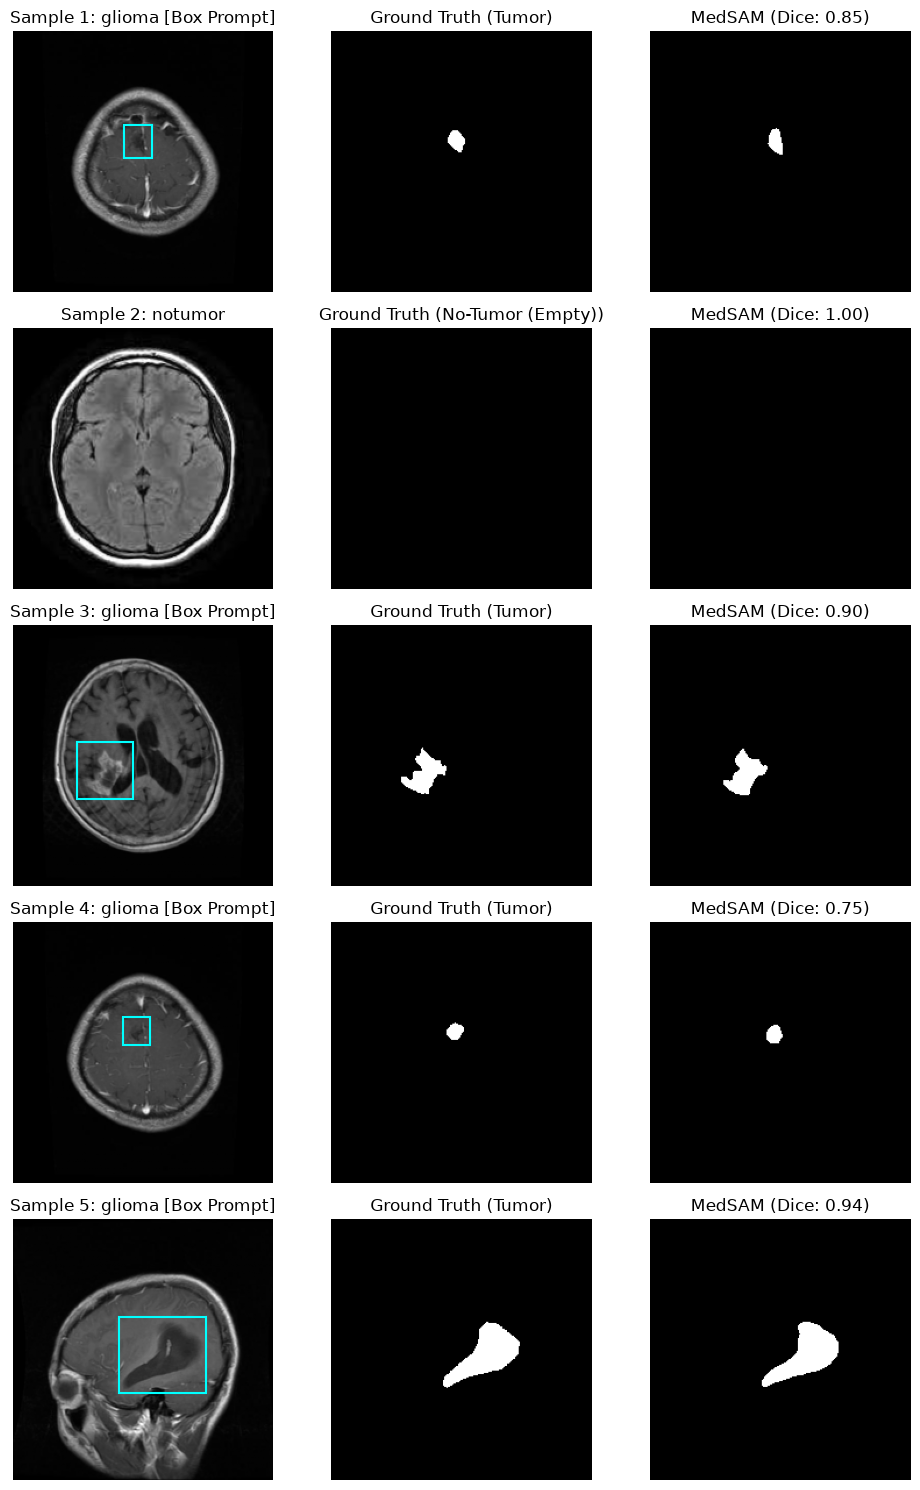

Saved Nov 8 checkpoint visualization to nov8_preliminary_5masks_medsam.png


In [2]:
# Helper inference function for MedSAM
@torch.no_grad()
def run_medsam_single(image_tensor_norm, gt_mask_tensor, has_mask, box_margin=5):
    img_gray = denormalize(image_tensor_norm.cpu()).numpy()
    H, W = img_gray.shape
    gt_np = gt_mask_tensor.squeeze().cpu().numpy()
    
    img_3c = np.repeat(img_gray[:, :, None], 3, axis=-1)
    img_tensor = torch.from_numpy(img_3c).float().permute(2, 0, 1).unsqueeze(0)
    img_1024 = F.interpolate(img_tensor, size=(1024, 1024), mode='bilinear', align_corners=False).to(device)
    
    image_embedding = medsam_model.image_encoder(img_1024)
    
    if has_mask and gt_np.sum() > 0:
        y_indices, x_indices = np.where(gt_np > 0)
        x_min = max(0, int(np.min(x_indices)) - box_margin)
        x_max = min(W, int(np.max(x_indices)) + box_margin)
        y_min = max(0, int(np.min(y_indices)) - box_margin)
        y_max = min(H, int(np.max(y_indices)) + box_margin)
        box_np = np.array([[x_min, y_min, x_max, y_max]])
        
        box_1024 = box_np / np.array([W, H, W, H]) * 1024
        box_torch = torch.as_tensor(box_1024, dtype=torch.float, device=device)[:, None, :]
        
        sparse_embeddings, dense_embeddings = medsam_model.prompt_encoder(
            points=None, boxes=box_torch, masks=None
        )
        low_res_logits, _ = medsam_model.mask_decoder(
            image_embeddings=image_embedding,
            image_pe=medsam_model.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse_embeddings,
            dense_prompt_embeddings=dense_embeddings,
            multimask_output=False,
        )
        low_res_pred = torch.sigmoid(low_res_logits)
        pred_interp = F.interpolate(
            low_res_pred, size=(H, W), mode='bilinear', align_corners=False
        ).squeeze().cpu().numpy()
        pred_mask = (pred_interp > 0.5).astype(np.float32)
        peak_prob = float(pred_interp.max())
    else:
        box_np = None
        pred_mask = np.zeros((H, W), dtype=np.float32)
        peak_prob = 0.0
        
    dice = compute_dice_score(torch.tensor(pred_mask), torch.tensor(gt_np))
    return pred_mask, dice, peak_prob, box_np, img_gray, gt_np

# Nov 8 Checkpoint: 5 samples from validation set
torch.manual_seed(42)
dev_loader = make_loader('dev', batch_size=5, shuffle=True)
batch = next(iter(dev_loader))

images = batch['image']
true_masks = batch['mask']
has_masks = batch['has_mask']
labels = batch['label']

fig, axes = plt.subplots(5, 3, figsize=(10, 15))

for i in range(5):
    cls_name = LABELS[labels[i]]
    pred_m, d_score, _, box_np, img_gray, gt_np = run_medsam_single(
        images[i], true_masks[i], has_masks[i].item()
    )
    has_m_str = "Tumor" if has_masks[i] else "No-Tumor (Empty)"
    
    # Col 1: Original MRI Slice + Prompt Bounding Box
    axes[i, 0].imshow(img_gray, cmap='gray')
    if box_np is not None:
        x0, y0, x1, y1 = box_np[0]
        rect = patches.Rectangle((x0, y0), x1 - x0, y1 - y0, linewidth=1.5, edgecolor='cyan', facecolor='none')
        axes[i, 0].add_patch(rect)
        axes[i, 0].set_title(f"Sample {i+1}: {cls_name} [Box Prompt]")
    else:
        axes[i, 0].set_title(f"Sample {i+1}: {cls_name}")
    axes[i, 0].axis('off')
    
    # Col 2: Ground Truth Mask
    axes[i, 1].imshow(gt_np, cmap='gray')
    axes[i, 1].set_title(f"Ground Truth ({has_m_str})")
    axes[i, 1].axis('off')
    
    # Col 3: MedSAM Predicted Mask
    axes[i, 2].imshow(pred_m, cmap='gray')
    axes[i, 2].set_title(f"MedSAM (Dice: {d_score:.2f})")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.savefig('nov8_preliminary_5masks_medsam.png', dpi=200)
plt.show()
print('Saved Nov 8 checkpoint visualization to nov8_preliminary_5masks_medsam.png')


### Nov 10 Checkpoint: 20-image visual inspection (5 per class), Dice score computed

Evaluating 20 held-out images on MedSAM...


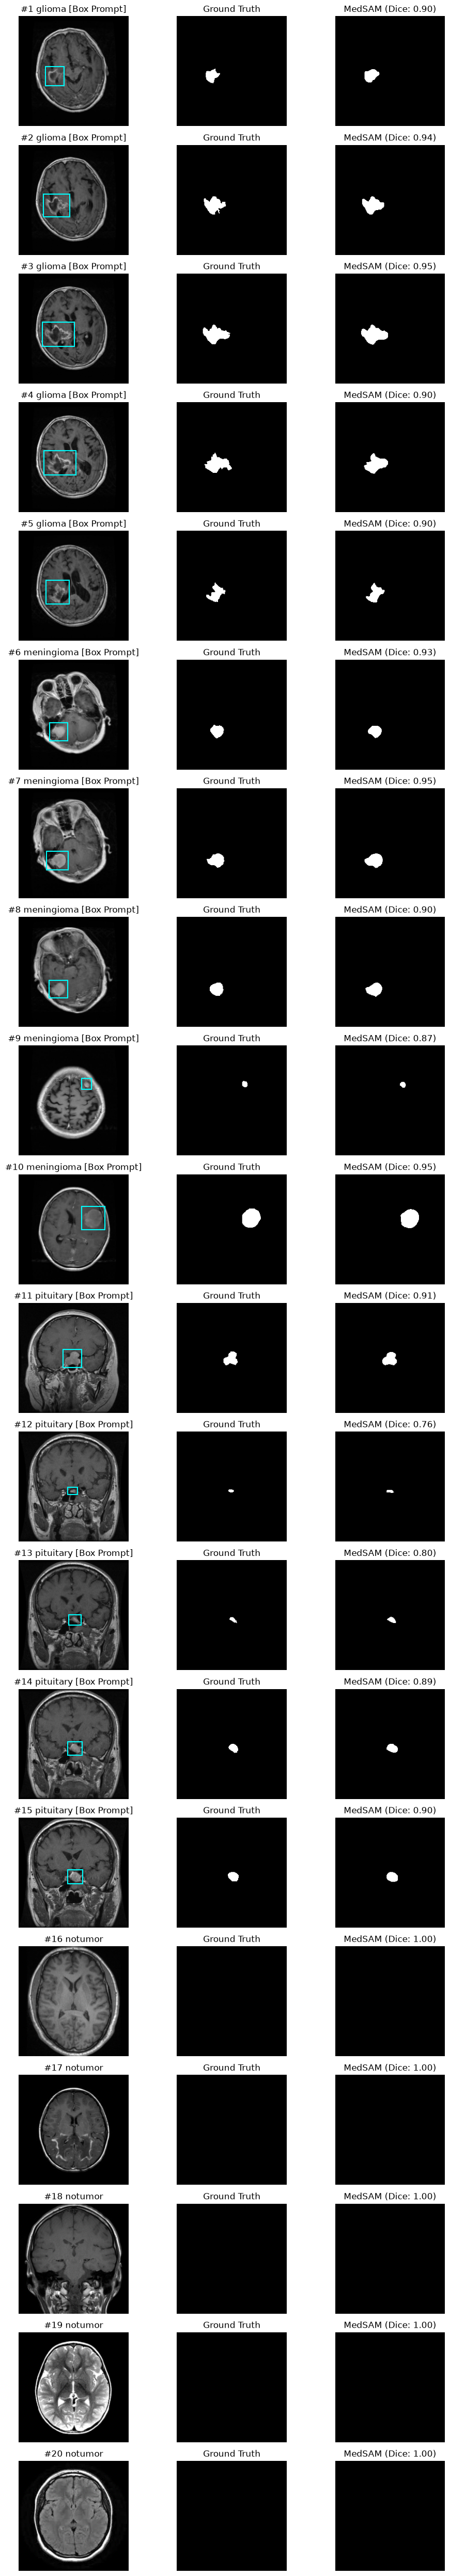


     NOV 10 MEDSAM MASK QUALITY EVALUATION TABLE
             dice  peak_prob
class                       
glioma      0.916        1.0
meningioma  0.921        1.0
notumor     1.000        0.0
pituitary   0.851        1.0

Overall Mean Dice on 20 Held-Out Images (MedSAM): 0.922


In [3]:
# Nov 10 Checkpoint: 20 held-out images (5 per class)
dev_dataset = BrainMRIDataset('dev')

class_indices = {c: [] for c in LABELS}
for idx in range(len(dev_dataset)):
    raw_label = dev_dataset.df.iloc[idx]['label']
    label_name = LABELS[raw_label] if isinstance(raw_label, int) else raw_label
    if len(class_indices[label_name]) < 5:
        class_indices[label_name].append(idx)
    if all(len(v) == 5 for v in class_indices.values()):
        break

selected_indices = [idx for c in LABELS for idx in class_indices[c]]

results = []
fig, axes = plt.subplots(20, 3, figsize=(10, 50))

print('Evaluating 20 held-out images on MedSAM...')

for row, idx in enumerate(selected_indices):
    sample = dev_dataset[idx]
    cls_name = LABELS[sample['label']]
    has_m = sample['has_mask']
    
    pred_m, d_score, peak_prob, box_np, img_gray, gt_np = run_medsam_single(
        sample['image'], sample['mask'], has_m
    )
    
    results.append({
        'sample_idx': idx,
        'class': cls_name,
        'has_mask': has_m,
        'dice': d_score,
        'peak_prob': peak_prob
    })
    
    # Col 1: Slice + Prompt Box
    axes[row, 0].imshow(img_gray, cmap='gray')
    if box_np is not None:
        x0, y0, x1, y1 = box_np[0]
        rect = patches.Rectangle((x0, y0), x1 - x0, y1 - y0, linewidth=1.5, edgecolor='cyan', facecolor='none')
        axes[row, 0].add_patch(rect)
        axes[row, 0].set_title(f"#{row+1} {cls_name} [Box Prompt]")
    else:
        axes[row, 0].set_title(f"#{row+1} {cls_name}")
    axes[row, 0].axis('off')
    
    # Col 2: Ground Truth
    axes[row, 1].imshow(gt_np, cmap='gray')
    axes[row, 1].set_title('Ground Truth')
    axes[row, 1].axis('off')
    
    # Col 3: MedSAM Mask
    axes[row, 2].imshow(pred_m, cmap='gray')
    axes[row, 2].set_title(f"MedSAM (Dice: {d_score:.2f})")
    axes[row, 2].axis('off')

plt.tight_layout()
plt.savefig('nov10_20image_mask_report_medsam.png', dpi=200)
plt.show()

# Print Table Summary
df_results = pd.DataFrame(results)
print('\n' + '='*50)
print('     NOV 10 MEDSAM MASK QUALITY EVALUATION TABLE')
print('='*50)
print(df_results.groupby('class')[['dice', 'peak_prob']].mean().round(3))
overall_dice = df_results['dice'].mean()
print(f'\nOverall Mean Dice on 20 Held-Out Images (MedSAM): {overall_dice:.3f}')
